In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pasta onde ficam as figuras usadas no relatório
os.makedirs("../markdown/figuras_churn", exist_ok=True)

# 1. Análise Exploratória dos dados (EDA)

In [2]:
dados = pd.read_csv("../../data/churn.csv")

print("Forma do dataframe: ", dados.shape)
dados.head()

Forma do dataframe:  (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,Yes
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,No
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,Yes
3,699,France,Female,39,1,0.00,2,0,0,93826.63,No
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,No


In [3]:
print("Tipo dos dados:\n")
print(dados.dtypes)

print("\nValores faltantes:", dados.isna().sum().sum())

Tipo dos dados:

CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited                 str
dtype: object

Valores faltantes: 0


In [4]:
dados.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000


## 1.1 Variável resposta (`Exited`)

In [5]:
contagem = dados["Exited"].value_counts()
total = len(dados)

print("Clientes que ficaram (No): ", contagem["No"], f"({contagem['No'] / total * 100:.1f}%)")
print("Clientes que saíram (Yes): ", contagem["Yes"], f"({contagem['Yes'] / total * 100:.1f}%)")

print(f"\nAcurácia de um 'modelo' que sempre prevê No: {contagem['No'] / total:.3f}")

Clientes que ficaram (No):  7963 (79.6%)
Clientes que saíram (Yes):  2037 (20.4%)

Acurácia de um 'modelo' que sempre prevê No: 0.796


## 1.2 Relação das variáveis com `Exited`

Geography:


           clientes  % que saíram
Geography                        
France         5014          16.2
Germany        2509          32.4
Spain          2477          16.7 

Gender:
        clientes  % que saíram
Gender                        
Female      4543          25.1
Male        5457          16.5 

HasCrCard:
           clientes  % que saíram
HasCrCard                        
0              2945          20.8
1              7055          20.2 

IsActiveMember:
                clientes  % que saíram
IsActiveMember                        
0                   4849          26.9
1                   5151          14.3 

NumOfProducts:
               clientes  % que saíram
NumOfProducts                        
1                  5084          27.7
2                  4590           7.6
3                   266          82.7
4                    60         100.0 



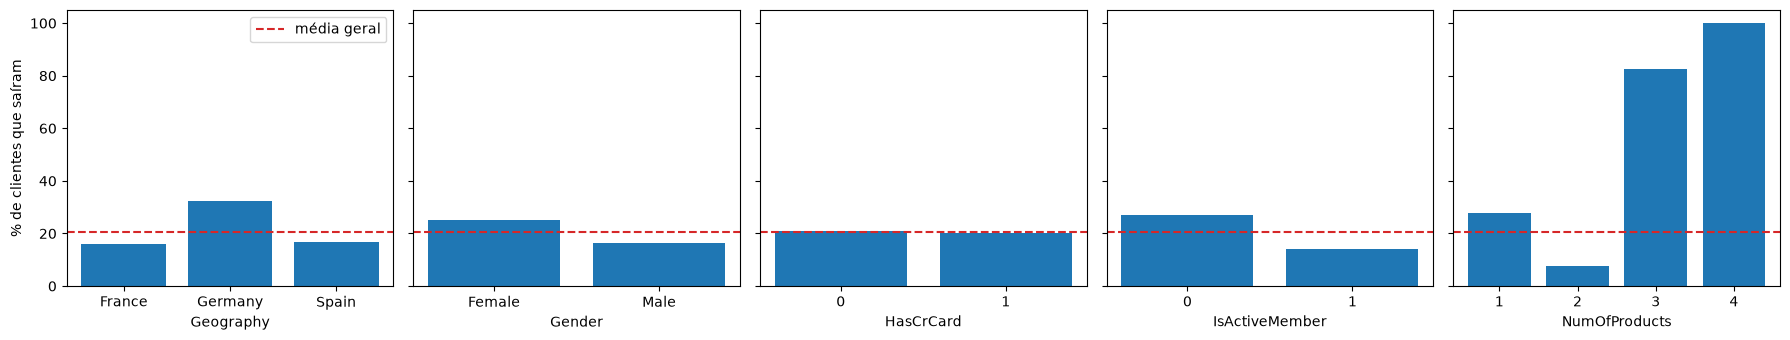

In [6]:
# Variável resposta em formato numérico: 1 = o cliente saiu (Yes), 0 = o cliente ficou (No)
y = (dados["Exited"] == "Yes").astype(int)

colunas_categoricas = ["Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts"]

# Porcentagem de clientes que saíram em cada categoria
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)

for ax, col in zip(axes, colunas_categoricas):
    taxa = y.groupby(dados[col]).mean() * 100

    ax.bar(taxa.index.astype(str), taxa.values)
    ax.axhline(y.mean() * 100, color="tab:red", linestyle="--", label="média geral")
    ax.set_xlabel(col)

    tabela = pd.DataFrame({"clientes": dados[col].value_counts(), "% que saíram": taxa.round(1)})
    print(f"{col}:")
    print(tabela.sort_index().to_string(), "\n")

axes[0].set_ylabel("% de clientes que saíram")
axes[0].legend()

plt.tight_layout()
plt.savefig("../markdown/figuras_churn/01_taxa_saida_por_categoria.png", dpi=150, bbox_inches="tight")
plt.show()

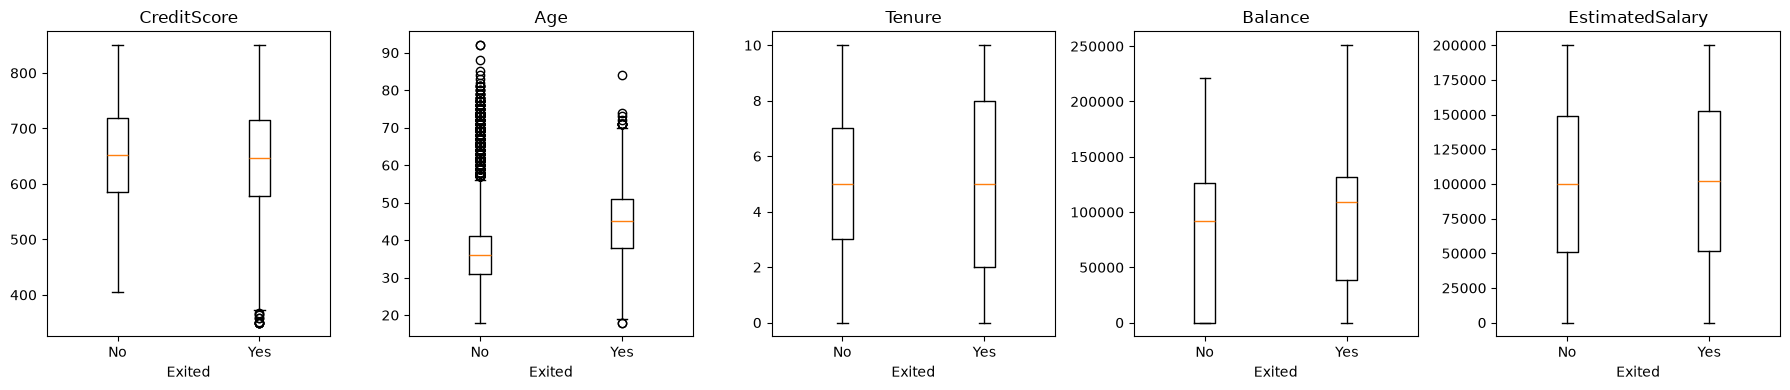

In [7]:
colunas_numericas = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, col in zip(axes, colunas_numericas):
    ax.boxplot([dados.loc[y == 0, col], dados.loc[y == 1, col]], tick_labels=["No", "Yes"])
    ax.set_xlabel("Exited")
    ax.set_title(col)

plt.tight_layout()
plt.savefig("../markdown/figuras_churn/02_boxplots_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Mediana de cada variável numérica por classe
dados.groupby("Exited")[colunas_numericas].median()

,CreditScore,Age,Tenure,Balance,EstimatedSalary
Exited,,,,,
No,653.0,36.0,5.0,92072.68,99645.04
Yes,646.0,45.0,5.0,109349.29,102460.84


# 2. Preparação dos dados

In [9]:
# Geography e Gender viram colunas 0/1 (dummies).
# drop_first=True descarta uma categoria de cada variável, para evitar colinearidade perfeita
X = pd.get_dummies(dados.drop(columns=["Exited"]), columns=["Geography", "Gender"], drop_first=True, dtype=int)

print("Formato de X:", X.shape)
X.head()

Formato de X: (10000, 11)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [10]:
from sklearn.model_selection import train_test_split

# Divisão 50/50. A estratificação mantém a mesma proporção de y = 1 no treino e no teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

print("Treino:", X_treino.shape, f"| % de y = 1: {y_treino.mean() * 100:.1f}")
print("Teste: ", X_teste.shape, f"| % de y = 1: {y_teste.mean() * 100:.1f}")

Treino: (5000, 11) | % de y = 1: 20.4
Teste:  (5000, 11) | % de y = 1: 20.4


In [11]:
from sklearn.preprocessing import StandardScaler

# k-NN e regressão logística são sensíveis à escala das variáveis (Balance chega a 250 mil e Age a 92).
# A média e o desvio-padrão são calculados SOMENTE no treino
escalonador = StandardScaler()
X_treino_pad = escalonador.fit_transform(X_treino)
X_teste_pad = escalonador.transform(X_teste)

# 3. Etapa de Treino

## 3.1 k-NN

**Regra de bolso para o k:** `k = raiz quadrada do número de observações de treino`, arredondado para um número ímpar para evitar empates na votação. Com 5.000 observações de treino, `k = 71`.

In [12]:
from sklearn.neighbors import KNeighborsClassifier

k = int(np.sqrt(len(X_treino)))
if k % 2 == 0:
    k = k + 1

print("k escolhido:", k)

knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_treino_pad, y_treino)

k escolhido: 71


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",71
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 3.2 Regressão Logística

In [13]:
from sklearn.linear_model import LogisticRegression

# C=np.inf = sem regularização (é o glm(..., family = binomial) do R)
logit_model = LogisticRegression(C=np.inf, max_iter=1000)
logit_model.fit(X_treino_pad, y_treino)

# Coeficientes na escala das variáveis padronizadas: efeito no log-odds de +1 desvio-padrão
coeficientes = pd.Series(logit_model.coef_[0], index=X.columns)
print("Intercepto:", round(logit_model.intercept_[0], 3))
coeficientes.sort_values().round(3)

Intercepto: -1.64


IsActiveMember      -0.521
Gender_Male         -0.273
CreditScore         -0.095
NumOfProducts       -0.031
HasCrCard           -0.029
Tenure              -0.020
EstimatedSalary      0.032
Geography_Spain      0.037
Balance              0.149
Geography_Germany    0.336
Age                  0.735
dtype: float64

## 3.3 Árvore de classificação

In [14]:
from sklearn.tree import DecisionTreeClassifier

# Árvore sem limite de crescimento (só para ver o que acontece)
arvore_cheia = DecisionTreeClassifier(criterion="entropy", random_state=42)
arvore_cheia.fit(X_treino, y_treino)

print("Profundidade:", arvore_cheia.get_depth())
print("Folhas:", arvore_cheia.get_n_leaves())
print(f"Acurácia no treino: {arvore_cheia.score(X_treino, y_treino):.3f}")

Profundidade: 25
Folhas: 699
Acurácia no treino: 1.000


A árvore sem limite decora o treino. Para controlar o sobreajuste, escolhemos o **número mínimo de observações por folha** com validação cruzada (5 partes) **usando só o treino**, pela AUC.

In [15]:
from sklearn.model_selection import GridSearchCV

busca = GridSearchCV(
    DecisionTreeClassifier(criterion="entropy", random_state=42),
    param_grid={"min_samples_leaf": [1, 5, 10, 20, 50, 100, 200]},
    scoring="roc_auc",
    cv=5,
)
busca.fit(X_treino, y_treino)

print("Melhor min_samples_leaf:", busca.best_params_["min_samples_leaf"])
print(f"AUC na validação cruzada: {busca.best_score_:.3f}")

tree_model = busca.best_estimator_
print("Folhas da árvore escolhida:", tree_model.get_n_leaves())

Melhor min_samples_leaf: 50
AUC na validação cruzada: 0.817
Folhas da árvore escolhida: 73


## 3.4 Random Forest

In [16]:
from sklearn.ensemble import RandomForestClassifier

# max_features padrão = raiz quadrada do número de variáveis (recomendação de Breiman para classificação)
forest_model = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
forest_model.fit(X_treino, y_treino)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## 3.5 Boosting

In [17]:
from sklearn.ensemble import GradientBoostingClassifier

# Hiperparâmetros usuais, fixados antes de olhar o teste
boosting_model = GradientBoostingClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42
)
boosting_model.fit(X_treino, y_treino)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

# 4. Etapa de Teste

## 4.1 Acurácia (corte de 50%) e curvas ROC

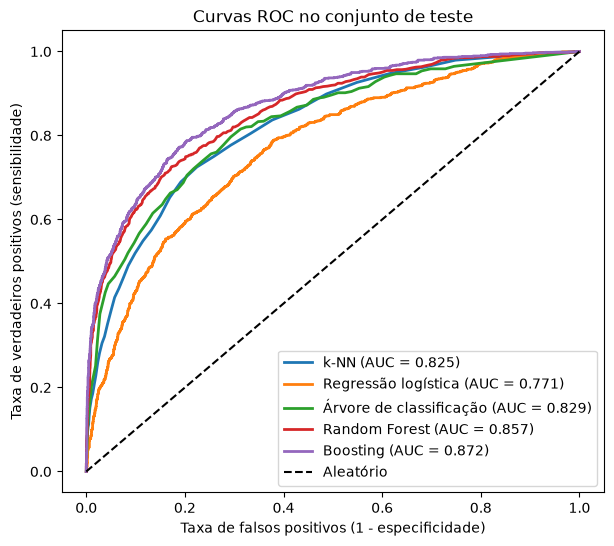

Acurácia de sempre prever No (referência): 0.796



,"Acurácia (corte 0,5)",Precision,Recall,AUC,% previstos como Yes
Modelo,,,,,
k-NN,0.821,0.842,0.151,0.825,3.66
Regressão logística,0.812,0.608,0.216,0.771,7.24
Árvore de classificação,0.841,0.643,0.487,0.829,15.42
Random Forest,0.858,0.719,0.499,0.857,14.14
Boosting,0.865,0.750,0.507,0.872,13.76


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve

# Cada modelo com os dados que ele usa (k-NN e regressão logística usam as variáveis padronizadas)
modelos = {
    "k-NN": (knn_model, X_teste_pad),
    "Regressão logística": (logit_model, X_teste_pad),
    "Árvore de classificação": (tree_model, X_teste),
    "Random Forest": (forest_model, X_teste),
    "Boosting": (boosting_model, X_teste),
}

resultados = []

plt.figure(figsize=(7, 6))

for nome, (modelo, X_modelo) in modelos.items():
    # Probabilidade prevista de o cliente sair (y = 1)
    prob = modelo.predict_proba(X_modelo)[:, 1]

    # Classificação com probabilidade de corte de 50%
    pred = (prob >= 0.5).astype(int)

    auc = roc_auc_score(y_teste, prob)
    fpr, tpr, _ = roc_curve(y_teste, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{nome} (AUC = {auc:.3f})")

    resultados.append({
        "Modelo": nome,
        "Acurácia (corte 0,5)": accuracy_score(y_teste, pred),
        "Precision": precision_score(y_teste, pred, zero_division=0),
        "Recall": recall_score(y_teste, pred),
        "AUC": auc,
        "% previstos como Yes": pred.mean() * 100,
    })

# Diagonal de referência: classificador aleatório (AUC = 0.5)
plt.plot([0, 1], [0, 1], "k--", label="Aleatório")

plt.xlabel("Taxa de falsos positivos (1 - especificidade)")
plt.ylabel("Taxa de verdadeiros positivos (sensibilidade)")
plt.title("Curvas ROC no conjunto de teste")
plt.legend(loc="lower right")

plt.savefig("../markdown/figuras_churn/03_curvas_roc.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Acurácia de sempre prever No (referência): {1 - y_teste.mean():.3f}\n")
pd.DataFrame(resultados).set_index("Modelo").round(3)

## 4.2 Verificação: regressão logística com `NumOfProducts` como categoria

Na análise exploratória, a taxa de saída por `NumOfProducts` não é monótona (27,7% com 1 produto, 7,6% com 2, 82,7% com 3 e 100% com 4), e o coeficiente linear dessa variável ficou quase zero. Para verificar se isso explica o mau desempenho da regressão logística, repetimos o ajuste tratando `NumOfProducts` como **categoria**. Este modelo **não entra na comparação principal**: serve só como diagnóstico.

In [19]:
# Mesma regressão logística, mas com NumOfProducts como categoria (colunas 0/1) em vez de numérica
X_cat = pd.get_dummies(
    dados.drop(columns=["Exited"]), columns=["Geography", "Gender", "NumOfProducts"], drop_first=True, dtype=int
)

# Mesmos parâmetros da divisão anterior, então as observações de treino e de teste são as mesmas
X_cat_treino, X_cat_teste, _, _ = train_test_split(X_cat, y, test_size=0.5, random_state=42, stratify=y)

escalonador_cat = StandardScaler()
X_cat_treino_pad = escalonador_cat.fit_transform(X_cat_treino)
X_cat_teste_pad = escalonador_cat.transform(X_cat_teste)

logit_cat_model = LogisticRegression(C=np.inf, max_iter=1000)
logit_cat_model.fit(X_cat_treino_pad, y_treino)

prob_cat = logit_cat_model.predict_proba(X_cat_teste_pad)[:, 1]
pred_cat = (prob_cat >= 0.5).astype(int)

print(f"Acurácia (corte 0,5): {accuracy_score(y_teste, pred_cat):.3f}")
print(f"Recall:               {recall_score(y_teste, pred_cat):.3f}")
print(f"AUC:                  {roc_auc_score(y_teste, prob_cat):.3f}")

Acurácia (corte 0,5): 0.843
Recall:               0.378
AUC:                  0.842


## 4.3 Árvore sem poda (só para comparação)

In [20]:
prob_cheia = arvore_cheia.predict_proba(X_teste)[:, 1]
pred_cheia = (prob_cheia >= 0.5).astype(int)

print(f"Acurácia no teste: {accuracy_score(y_teste, pred_cheia):.3f}")
print(f"AUC no teste:      {roc_auc_score(y_teste, prob_cheia):.3f}")

Acurácia no teste: 0.792
AUC no teste:      0.692


## 4.4 Importância das variáveis na Random Forest

In [21]:
# Importância por redução de impureza, normalizada para somar 1
importancia = pd.Series(forest_model.feature_importances_, index=X.columns)
importancia.sort_values(ascending=False).round(3)

Age                  0.237
EstimatedSalary      0.148
CreditScore          0.141
Balance              0.141
NumOfProducts        0.128
Tenure               0.083
IsActiveMember       0.038
Geography_Germany    0.028
Gender_Male          0.020
HasCrCard            0.020
Geography_Spain      0.015
dtype: float64